In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

sim = AerSimulator()
SHOTS = 100

## Predictions (before running)
- Part A (H, CNOT): Bell state (|00> + |11>)/sqrt(2). I expect 00 and 11 to dominate, about 50% each.
- Part B (H, CNOT, X on q1): State (|01> + |10>)/sqrt(2). I expect 01 and 10 to dominate, about 50% each.
- Will all four outcomes appear? No. In each circuit only two outcomes appear, because the qubits are entangled and perfectly correlated. The other two outcomes have probability 0 on an ideal simulator.
- Why are some outcomes much more frequent? Entanglement links the two qubits, so only certain combinations are allowed by the state.

In [ ]:
## Part A: Correlated outcomes (00 and 11)

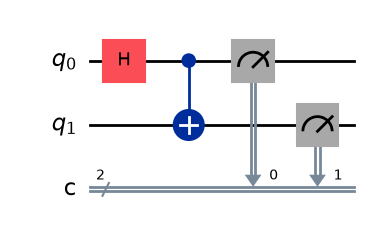

In [2]:
qc_a = QuantumCircuit(2, 2, name="Part A")
qc_a.h(0)
qc_a.cx(0, 1)
qc_a.measure([0, 1], [0, 1])

display(qc_a.draw("mpl"))

Part A results: {'00': 50, '11': 50}


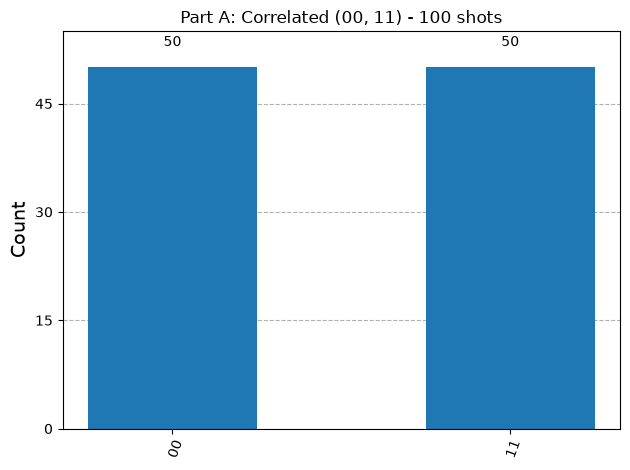

In [3]:
counts_a = sim.run(qc_a, shots=SHOTS).result().get_counts()
print("Part A results:", counts_a)
display(plot_histogram(counts_a, title="Part A: Correlated (00, 11) - 100 shots"))

In [ ]:
## Part B: Opposite outcomes (01 and 10)

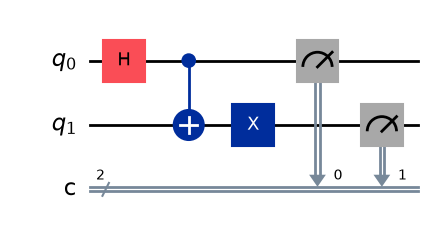

In [4]:
qc_b = QuantumCircuit(2, 2, name="Part B")
qc_b.h(0)
qc_b.cx(0, 1)
qc_b.x(1)          # the switch: flips q1
qc_b.measure([0, 1], [0, 1])

display(qc_b.draw("mpl"))

Part B results: {'10': 53, '01': 47}


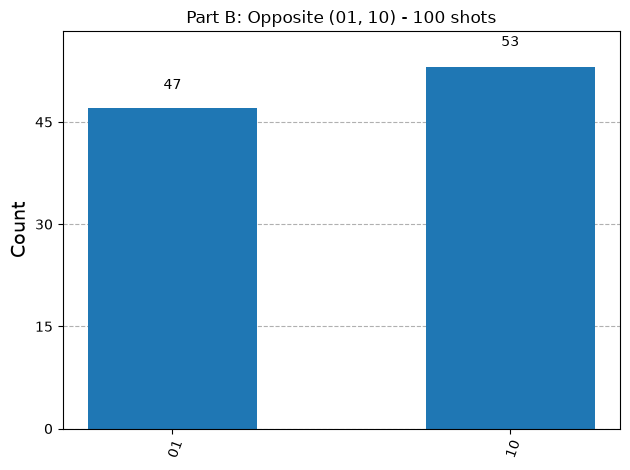

In [5]:
counts_b = sim.run(qc_b, shots=SHOTS).result().get_counts()
print("Part B results:", counts_b)
display(plot_histogram(counts_b, title="Part B: Opposite (01, 10) - 100 shots"))

In [ ]:
## Part C: Compare

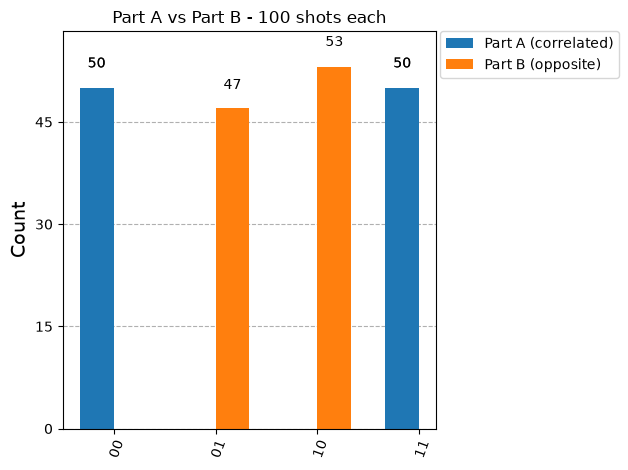

In [6]:
plot_histogram([counts_a, counts_b],
               legend=["Part A (correlated)", "Part B (opposite)"],
               title="Part A vs Part B - 100 shots each")

In [ ]:
## Comparison and Explanation
- Dominant outcomes in Part A: 00 and 11 (about 50% each). Actual: {write your counts}.
- Dominant outcomes in Part B: 01 and 10 (about 50% each). Actual: {write your counts}.
- What changed between the circuits: Only one extra gate, an X gate on qubit 1, placed after the CNOT.
- Why the relationship changed: The H gate puts q0 in superposition and the CNOT entangles the qubits, producing (|00> + |11>)/sqrt(2), where both qubits always agree. The X gate flips q1 in every term, turning the state into (|01> + |10>)/sqrt(2), where the qubits always disagree. So the X gate works as a switch between "same" and "opposite". Each qubit alone is still random (50/50), but their relationship is fixed by entanglement.
- Prediction check: Both predictions matched. Only two of the four outcomes appeared in each experiment. (Qiskit prints bits as q1 q0.)